#AI-Based Fabric Defect Detection and Quality Inspection System


## 1. Setup

In [ ]:
import os, json, random, hashlib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR  = "/content/drive/MyDrive/Fabric_Defect_Project"
DATASET_PATH = f"{PROJECT_DIR}/Fabric Defect Dataset"
SPLIT_FILE   = f"{PROJECT_DIR}/split.json"          # saved so the test set never changes
MODEL_P1     = f"{PROJECT_DIR}/fabric_phase1.keras"
MODEL_FINAL  = f"{PROJECT_DIR}/best_fabric_model.keras"
CLASSES_FILE = f"{PROJECT_DIR}/class_names.json"

IMG_SIZE, BATCH_SIZE = (224, 224), 16
EXTS = (".jpg", ".jpeg", ".png", ".bmp")

# sorted() -> same order every session (same as Keras' alphabetical order)
class_names = sorted(d for d in os.listdir(DATASET_PATH)
                     if os.path.isdir(os.path.join(DATASET_PATH, d)))
NUM_CLASSES = len(class_names)
class_to_label = {n: i for i, n in enumerate(class_names)}
DEFECT_FREE = "defect free"
assert DEFECT_FREE in class_names
print(class_names)

Mounted at /content/drive
['Vertical', 'defect free', 'hole', 'horizontal', 'lines', 'stain']


## 2. Explore the data

{'Vertical': 101, 'defect free': 192, 'hole': 268, 'horizontal': 136, 'lines': 174, 'stain': 328} | total: 1199


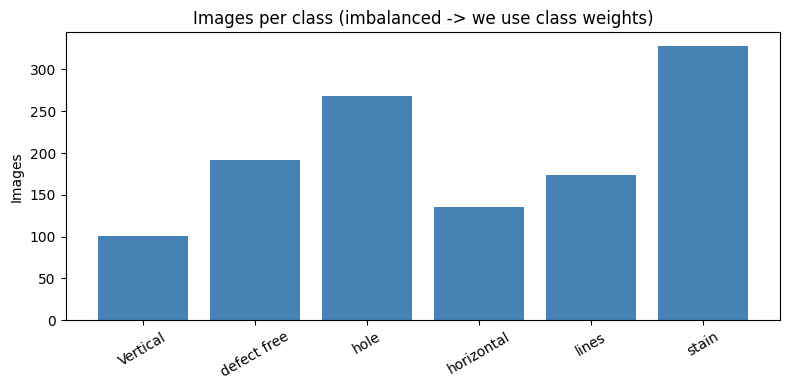

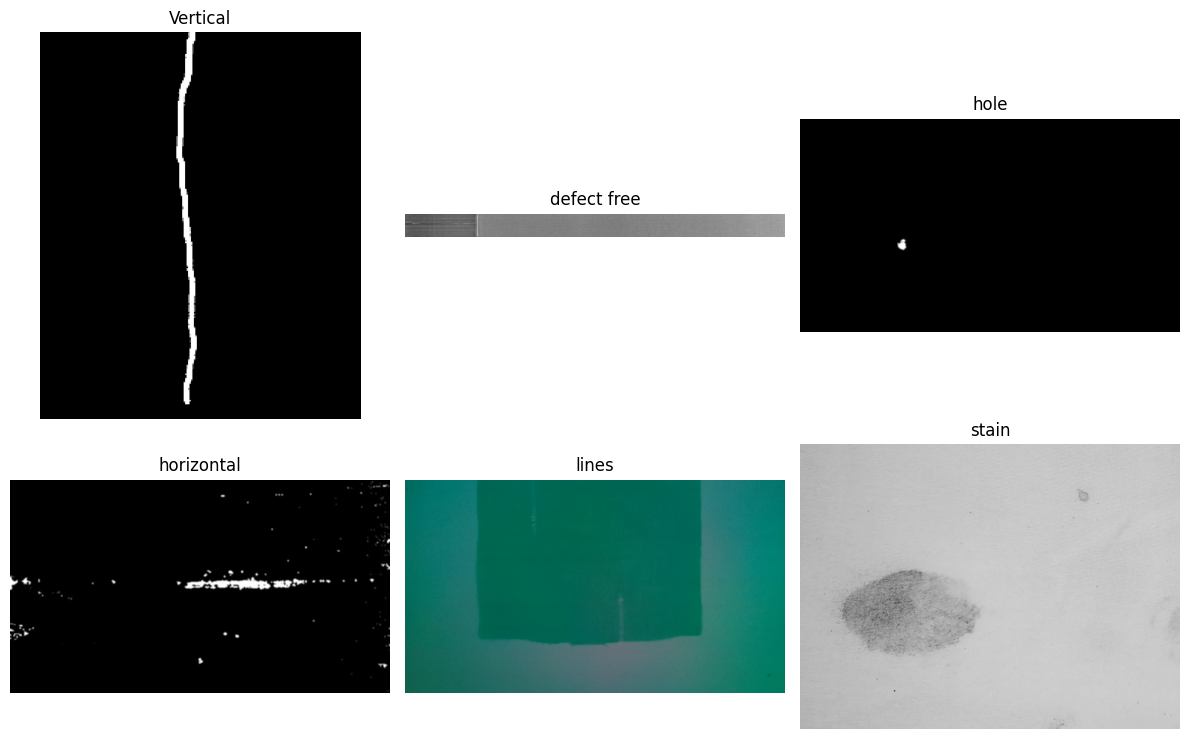

In [ ]:
counts = {}
for c in class_names:
    counts[c] = len([f for f in os.listdir(os.path.join(DATASET_PATH, c)) if f.lower().endswith(EXTS)])
print(counts, "| total:", sum(counts.values()))

plt.figure(figsize=(8,4))
plt.bar(counts.keys(), counts.values(), color="steelblue")
plt.title("Images per class (imbalanced -> we use class weights)")
plt.ylabel("Images"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

# one random sample per class
plt.figure(figsize=(12,8))
for i, c in enumerate(class_names):
    folder = os.path.join(DATASET_PATH, c)
    f = random.choice([x for x in os.listdir(folder) if x.lower().endswith(EXTS)])
    plt.subplot(2,3,i+1); plt.imshow(tf.keras.utils.load_img(os.path.join(folder, f)))
    plt.title(c); plt.axis("off")
plt.tight_layout(); plt.show()

## 3. Leak-free train / validation / test split
Fixes over the first version: files are **sorted** before splitting (so `os.listdir` order can't change the split between sessions), the split is **stratified**, and it is **saved to Drive** so evaluation always uses the identical test set. We also check for exact duplicate images across splits.

In [4]:
all_paths, all_labels = [], []
for c in class_names:
    folder = os.path.join(DATASET_PATH, c)
    for f in sorted(os.listdir(folder)):
        if f.lower().endswith(EXTS):
            all_paths.append(os.path.join(folder, f)); all_labels.append(class_to_label[c])

if os.path.exists(SPLIT_FILE):
    split = json.load(open(SPLIT_FILE))
    print("Loaded existing split")
else:
    p_tr, p_tmp, y_tr, y_tmp = train_test_split(all_paths, all_labels, test_size=0.30,
                                                stratify=all_labels, random_state=SEED)
    p_va, p_te, y_va, y_te = train_test_split(p_tmp, y_tmp, test_size=0.50,
                                              stratify=y_tmp, random_state=SEED)
    split = {"train": [p_tr, y_tr], "val": [p_va, y_va], "test": [p_te, y_te]}
    json.dump(split, open(SPLIT_FILE, "w"))
    json.dump(class_names, open(CLASSES_FILE, "w"))
    print("Created and saved new split")

for k, (p, y) in split.items():
    print(f"{k:5s}: {len(p):4d} images | per class:", np.bincount(y, minlength=NUM_CLASSES))

# exact-duplicate check across splits (inflated accuracy warning)
def md5(p): return hashlib.md5(open(p, "rb").read()).hexdigest()
hash_split = {}
for k, (p, _) in split.items():
    for path in p: hash_split.setdefault(md5(path), set()).add(k)
leaks = sum(1 for s in hash_split.values() if len(s) > 1)
print("\nIdentical images appearing in more than one split:", leaks)

Loaded existing split
train:  839 images | per class: [ 71 134 188  95 122 229]
val  :  180 images | per class: [15 29 40 20 26 50]
test :  180 images | per class: [15 29 40 21 26 49]

Identical images appearing in more than one split: 21


## 4. Input pipelines

In [5]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    return tf.cast(img, tf.float32), label

def make_ds(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training: ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_data = make_ds(*split["train"], training=True)
val_data   = make_ds(*split["val"])
test_data  = make_ds(*split["test"])

# class weights to compensate for imbalance (stain 328 vs Vertical 101)
y_train = np.array(split["train"][1])
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weight = {i: float(w) for i, w in enumerate(cw)}
print("Class weights:", {class_names[i]: round(w, 2) for i, w in class_weight.items()})

Class weights: {'Vertical': 1.97, 'defect free': 1.04, 'hole': 0.74, 'horizontal': 1.47, 'lines': 1.15, 'stain': 0.61}


## 5. Model: MobileNetV2 transfer learning with augmentation
Note: rotation is kept small (≈ ±11°) because **horizontal** and **Vertical** defects are separated by orientation — a 90° rotation would change the label. Flips are safe.

In [6]:
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augmentation")

backbone = tf.keras.applications.MobileNetV2(input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet")
base = tf.keras.Model(backbone.input, backbone.output, name="mobilenet_base")
base.trainable = False

head = tf.keras.Sequential([
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(NUM_CLASSES, activation="softmax"),
], name="classifier_head")

inputs = layers.Input(shape=(*IMG_SIZE, 3))
x = augment(inputs)                                  # only active during training
x = layers.Rescaling(1/127.5, offset=-1)(x)          # MobileNetV2 preprocessing
x = base(x)
outputs = head(x)
model = tf.keras.Model(inputs, outputs, name="fabric_defect_classifier")

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "fabric_defect_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_base (Functional)     │ (None, 7, 7, 1280)     │     2,257,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_head (Sequential)    │ (None, 6)              │       164,742 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Phase 1 – train only the new classifier head

In [ ]:
cb1 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_P1, monitor="val_loss", save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
]
hist1 = model.fit(train_data, validation_data=val_data, epochs=25,
                  class_weight=class_weight, callbacks=cb1)

Epoch 1/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 27s 275ms/step - accuracy: 0.6985 - loss: 0.8592 - val_accuracy: 0.8278 - val_loss: 0.4292 - learning_rate: 0.0010
Epoch 2/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 12s 232ms/step - accuracy: 0.8248 - loss: 0.4653 - val_accuracy: 0.8833 - val_loss: 0.2899 - learning_rate: 0.0010
Epoch 3/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 11s 205ms/step - accuracy: 0.8498 - loss: 0.3720 - val_accuracy: 0.9278 - val_loss: 0.2639 - learning_rate: 0.0010
Epoch 4/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 23s 255ms/step - accuracy: 0.8808 - loss: 0.3161 - val_accuracy: 0.8833 - val_loss: 0.2619 - learning_rate: 0.0010
Epoch 5/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 13s 253ms/step - accuracy: 0.8772 - loss: 0.3283 - val_accuracy: 0.9111 - val_loss: 0.2383 - learning_rate: 0.0010
Epoch 6/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 12s 222ms/step - accuracy: 0.8975 - loss: 0.2608 - val_accuracy: 0.9056 - val_loss: 0.2449 - learning_rate: 0.0010
Epoch 7/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 12s 234ms/step - accuracy: 0.8856 - loss: 0.

### Phase 2 – fine-tune the top of MobileNetV2 with a very small learning rate

In [ ]:
base.trainable = True
for layer in base.layers[:-30]:          # keep early layers frozen
    layer.trainable = False
for layer in base.layers:                # keep BatchNorm frozen (stable with small data)
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

cb2 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_FINAL, monitor="val_loss", save_best_only=True),
]
hist2 = model.fit(train_data, validation_data=val_data, epochs=20,
                  class_weight=class_weight, callbacks=cb2)
print("Best model saved to:", MODEL_FINAL)

In [ ]:
def plot_history(*hists):
    acc  = sum([h.history["accuracy"] for h in hists], [])
    vacc = sum([h.history["val_accuracy"] for h in hists], [])
    loss = sum([h.history["loss"] for h in hists], [])
    vloss= sum([h.history["val_loss"] for h in hists], [])
    split_at = len(hists[0].history["loss"])
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, tr, va, t in [(ax[0], acc, vacc, "Accuracy"), (ax[1], loss, vloss, "Loss")]:
        a.plot(tr, label="train"); a.plot(va, label="validation")
        a.axvline(split_at-1, color="gray", ls="--", label="start fine-tuning")
        a.set_title(t); a.set_xlabel("Epoch"); a.legend()
    plt.tight_layout(); plt.show()

plot_history(hist1, hist2)

## 6. Evaluation on the untouched test set

In [ ]:
model = tf.keras.models.load_model(MODEL_FINAL)
base, head = model.get_layer("mobilenet_base"), model.get_layer("classifier_head")

test_loss, test_acc = model.evaluate(test_data, verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc*100:.2f}%")

probs  = model.predict(test_data, verbose=0)
y_pred = probs.argmax(1)
y_true = np.array(split["test"][1])      # same order as test_data (not shuffled)

print(classification_report(y_true, y_pred, target_names=class_names, digits=3, zero_division=0))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("6-class confusion matrix")
plt.tight_layout(); plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from google.colab import files

# get true labels and predicted probabilities for the test set
y_true, y_score = [], []
for images, labels in test_data:
    y_score.extend(model.predict(images, verbose=0))
    y_true.extend(labels.numpy())
y_true = np.array(y_true)
y_score = np.array(y_score)

# one curve per class
y_bin = label_binarize(y_true, classes=list(range(len(class_names))))
plt.figure(figsize=(7, 6))
for i, name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves (one-vs-rest)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("roc_auc.png", dpi=200)
plt.show()

files.download("roc_auc.png")

### Quality-inspection view: PASS / FAIL (defect-free vs any defect)

In [ ]:
ok = class_names.index(DEFECT_FREE)
t_bin = (y_true != ok).astype(int)      # 1 = defective
p_bin = (y_pred != ok).astype(int)
print(classification_report(t_bin, p_bin, target_names=["PASS (defect free)", "FAIL (defective)"], digits=3))
missed = int(((t_bin == 1) & (p_bin == 0)).sum())
print("Defective fabrics wrongly passed (most costly error):", missed)

In [ ]:
# look at the mistakes
wrong = np.where(y_pred != y_true)[0]
print("Misclassified:", len(wrong))
plt.figure(figsize=(14, 3.2 * ((min(len(wrong), 10) + 4)//5)))
for k, i in enumerate(wrong[:10]):
    plt.subplot(2, 5, k+1)
    plt.imshow(tf.keras.utils.load_img(split["test"][0][i], target_size=IMG_SIZE))
    plt.title(f"True: {class_names[y_true[i]]}\nPred: {class_names[y_pred[i]]}", fontsize=9); plt.axis("off")
plt.tight_layout(); plt.show()

## 7. Defect localisation with Grad-CAM
A classifier only says *what* is wrong; Grad-CAM highlights *where* the model looked, which turns the project into actual defect **detection** and makes the results explainable.

In [ ]:
def gradcam(arr, class_idx=None):
    x = tf.convert_to_tensor(arr[None], dtype=tf.float32) / 127.5 - 1.0
    with tf.GradientTape() as tape:
        conv = base(x, training=False)
        tape.watch(conv)
        preds = head(conv, training=False)
        if class_idx is None: class_idx = int(tf.argmax(preds[0]))
        score = preds[:, class_idx]
    grads = tape.gradient(score, conv)
    w = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], IMG_SIZE)[..., 0].numpy()
    return cam

def inspect_fabric(path_or_array, threshold=0.70, show=True):
    arr = (np.array(tf.keras.utils.load_img(path_or_array, target_size=IMG_SIZE), dtype=np.float32)
           if isinstance(path_or_array, str) else path_or_array.astype(np.float32))
    p = model.predict(arr[None], verbose=0)[0]
    idx = int(p.argmax()); conf = float(p[idx]); label = class_names[idx]
    if conf < threshold:       verdict = "MANUAL REVIEW (low confidence)"
    elif label == DEFECT_FREE: verdict = "PASS"
    else:                      verdict = "FAIL"
    result = {"verdict": verdict, "predicted_class": label, "confidence": round(conf*100, 2),
              "all_probabilities": {c: round(float(v)*100, 2) for c, v in zip(class_names, p)}}
    if show:
        cam = gradcam(arr, idx)
        fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
        ax[0].imshow(arr.astype("uint8")); ax[0].set_title("Input"); ax[0].axis("off")
        ax[1].imshow(arr.astype("uint8")); ax[1].imshow(cam, cmap="jet", alpha=0.45)
        ax[1].set_title(f"{verdict}\n{label} ({conf*100:.1f}%)"); ax[1].axis("off")
        plt.tight_layout(); plt.show()
    return result

# demo on 4 random test images (no upload needed)
for i in random.sample(range(len(split["test"][0])), 4):
    print("Actual:", class_names[y_true[i]])
    print(inspect_fabric(split["test"][0][i]), "\n")

### Try your own fabric image (optional upload)

In [ ]:
from google.colab import files
uploaded = files.upload()          # choose an image, then wait for the upload bar to finish
if uploaded:
    print(inspect_fabric(list(uploaded.keys())[0]))

## 8. Web demo with Gradio

In [ ]:
!pip -q install gradio
import gradio as gr

def ui_predict(img):
    arr = np.array(tf.image.resize(img, IMG_SIZE), dtype=np.float32)
    r = inspect_fabric(arr, show=False)
    cam = gradcam(arr)
    heat = plt.get_cmap("jet")(cam)[..., :3] * 255
    overlay = (0.55 * arr + 0.45 * heat).astype("uint8")
    return f"{r['verdict']}  -  {r['predicted_class']} ({r['confidence']}%)", overlay

demo = gr.Interface(fn=ui_predict, inputs=gr.Image(label="Fabric image"),
                    outputs=[gr.Textbox(label="Inspection result"), gr.Image(label="Defect heat-map")],
                    title="Fabric Defect Inspection")
demo.launch(share=True, debug=False)

## 9. Summary for the report
Fill in from your outputs: dataset (1,199 images, 6 classes) · split 70/15/15 stratified · MobileNetV2 + augmentation + class weights · 2-phase training · test accuracy ___ % · macro-F1 ___ · defective-fabric miss rate ___ · limitations (small test set, single dataset, classification + Grad-CAM rather than bounding-box detection) · future work (YOLO with box labels, real-time camera feed, edge deployment).